# 09 — PushT: Visuomotor Imitation Learning

## Learning Objectives

In this notebook, we train imitation learning policies on
the PushT benchmark using visual observations.

We progressively implement:

1. A CNN-based visuomotor Behavior Cloning policy.
2. A deterministic action-chunking policy.
3. A simplified ACT architecture with a CVAE and Transformer.

All policies use the same PushT dataset and observation modalities.

We will evaluate both prediction quality and closed-loop
behavior in the simulation environment.

## 1. Visuomotor Behavior Cloning

A visuomotor policy maps visual observations and robot state
to actions:

$$
\hat a_t = \pi_\theta(I_t, s_t)
$$

where:

- $I_t \in \mathbb{R}^{3 \times 96 \times 96}$ is the RGB image.
- $s_t \in \mathbb{R}^{2}$ is the agent position.
- $\hat a_t \in \mathbb{R}^{2}$ is the predicted action target.

We train the policy by minimizing the mean squared error
between predicted actions and expert commands:

$$
\mathcal{L}_{BC} =
\mathbb{E}_{(I_t,s_t,a_t)\sim D}
\left[\|\pi_\theta(I_t,s_t)-a_t\|_2^2\right]
$$

Unlike the previous PointRobot experiments, the policy
must extract task-relevant information from images.

The visual encoder must implicitly represent the object's
position, orientation, and relationship to the target.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import torch
from torch.utils.data import DataLoader

from lerobot.datasets.lerobot_dataset import LeRobotDataset

device = torch.device(
    "mps" if torch.backends.mps.is_available() else "cpu"
)

print("Device:", device)

/Users/terreran/Documents/ws-playground/robot-learning-playground/.pixi/envs/default/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Device: mps


In [2]:
dataset = LeRobotDataset("lerobot/pusht")

batch_size = 32

dataloader = DataLoader(
    dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0,
)

batch = next(iter(dataloader))

images = batch["observation.image"]
states = batch["observation.state"]
actions = batch["action"]

print("Images:", images.shape)
print("States:", states.shape)
print("Actions:", actions.shape)

print("Image range:", images.min().item(), images.max().item())
print("State range:", states.min().item(), states.max().item())
print("Action range:", actions.min().item(), actions.max().item())

Fetching 4 files: 100%|██████████| 4/4 [00:00<00:00, 1183.41it/s]


Images: torch.Size([32, 3, 96, 96])
States: torch.Size([32, 2])
Actions: torch.Size([32, 2])
Image range: 0.0 1.0
State range: 40.735904693603516 448.37255859375
Action range: 47.0 439.0


### 1.1 Train/Validation Split

Robot demonstration datasets contain temporally correlated samples.

Randomly splitting individual frames can introduce data leakage:
frames from the same demonstration may appear in both training
and validation sets.

Instead, we split the dataset at the episode level.

We use:

- 80% of episodes for training.
- 20% of episodes for validation.
- A fixed random seed for reproducibility.

Normalization statistics will be computed using only
the training subset.

In [3]:
from torch.utils.data import Subset

rng = np.random.default_rng(42)

n_episodes = dataset.meta.total_episodes
episode_ids = rng.permutation(n_episodes)

n_train_episodes = int(0.8 * n_episodes)

train_episode_ids = episode_ids[:n_train_episodes]
val_episode_ids = episode_ids[n_train_episodes:]

# Use episode metadata to identify frame ranges.
episode_ranges = dataset.meta.episodes

train_indices = []
val_indices = []

for episode_id in train_episode_ids:
    info = episode_ranges[int(episode_id)]
    train_indices.extend(
        range(int(info["dataset_from_index"]), int(info["dataset_to_index"]))
    )

for episode_id in val_episode_ids:
    info = episode_ranges[int(episode_id)]
    val_indices.extend(
        range(int(info["dataset_from_index"]), int(info["dataset_to_index"]))
    )

train_dataset = Subset(dataset, train_indices)
val_dataset = Subset(dataset, val_indices)

print("Training episodes:", len(train_episode_ids))
print("Validation episodes:", len(val_episode_ids))
print("Training frames:", len(train_dataset))
print("Validation frames:", len(val_dataset))

Training episodes: 164
Validation episodes: 42
Training frames: 20719
Validation frames: 4931


### 1.2 State and Action Normalization

State and action coordinates have a much larger numerical
scale than image pixel values.

We normalize states and actions using training-set statistics:

$$
\tilde{s} = \frac{s-\mu_s}{\sigma_s}
$$

$$
\tilde{a} = \frac{a-\mu_a}{\sigma_a}
$$

This improves numerical conditioning during optimization.

At inference time, predicted actions must be converted
back to the original environment coordinates.

In [4]:
train_states = torch.stack([
    dataset[i]["observation.state"]
    for i in train_indices
])

train_actions = torch.stack([
    dataset[i]["action"]
    for i in train_indices
])

state_mean = train_states.mean(dim=0)
state_std = train_states.std(dim=0).clamp(min=1e-6)

action_mean = train_actions.mean(dim=0)
action_std = train_actions.std(dim=0).clamp(min=1e-6)

print("State mean:", state_mean)
print("State std:", state_std)
print("Action mean:", action_mean)
print("Action std:", action_std)

State mean: tensor([229.3067, 293.6066])
State std: tensor([101.0137,  96.2644])
Action mean: tensor([228.4061, 294.3032])
Action std: tensor([100.6740,  95.7861])


### 1.3 Visual Encoder

A visuomotor policy must extract task-relevant information
from visual observations.

We use a Convolutional Neural Network (CNN) to encode
the RGB image into a compact feature vector:

$$
v_t = f_\theta(I_t)
$$

where:

- $I_t \in \mathbb{R}^{3 \times 96 \times 96}$
- $v_t \in \mathbb{R}^{128}$

The visual encoder is trained jointly with the policy.

Unlike a pretrained vision model, this CNN learns visual
representations directly from the imitation learning objective.

In [5]:
import torch
import torch.nn as nn

class VisualEncoder(nn.Module):
    def __init__(self, feature_dim=128):
        super().__init__()

        self.cnn = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=5, stride=2, padding=2),
            nn.ReLU(),

            nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d((4, 4)),
            nn.Flatten(),
        )

        self.projection = nn.Sequential(
            nn.Linear(128 * 4 * 4, feature_dim),
            nn.ReLU(),
        )

    def forward(self, images):
        features = self.cnn(images)
        return self.projection(features)

In [6]:
visual_encoder = VisualEncoder(feature_dim=128).to(device)

with torch.no_grad():
    visual_features = visual_encoder(
        images.to(device)
    )

print("Input images:", images.shape)
print("Visual features:", visual_features.shape)

Input images: torch.Size([32, 3, 96, 96])
Visual features: torch.Size([32, 128])


### 1.4 Visuomotor Behavior Cloning Policy

We combine visual features with the normalized agent state.

The policy predicts a normalized 2D action:

$$
\hat{\tilde a}_t =
g_\theta\left(
[f_\theta(I_t), \tilde s_t]
\right)
$$

where $[\cdot,\cdot]$ denotes feature concatenation.

The predicted action is converted back to environment
coordinates using:

$$
\hat a_t =
\hat{\tilde a}_t \odot \sigma_a + \mu_a
$$

The CNN and MLP are trained jointly using Behavior Cloning.

In [7]:
class VisuomotorBC(nn.Module):
    def __init__(self, visual_dim=128):
        super().__init__()

        self.visual_encoder = VisualEncoder(
            feature_dim=visual_dim
        )

        self.policy_head = nn.Sequential(
            nn.Linear(visual_dim + 2, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, 2),
        )

    def forward(self, images, states):
        visual_features = self.visual_encoder(images)

        features = torch.cat(
            [visual_features, states],
            dim=-1,
        )

        return self.policy_head(features)

In [8]:
bc_policy = VisuomotorBC().to(device)

normalized_states = (
    states.to(device) - state_mean.to(device)
) / state_std.to(device)

with torch.no_grad():
    predicted_actions = bc_policy(
        images.to(device),
        normalized_states,
    )

print("Predicted actions:", predicted_actions.shape)
print("Example prediction:", predicted_actions[0])
print("Number of parameters:",
      sum(p.numel() for p in bc_policy.parameters()))

Predicted actions: torch.Size([32, 2])
Example prediction: tensor([-0.0490,  0.0619], device='mps:0')
Number of parameters: 456898


### 1.5 Training the Visuomotor BC Policy

We train the visual encoder and policy head jointly using
expert demonstrations.

The model predicts normalized actions:

$$
\hat{\tilde a}_t = \pi_\theta(I_t, \tilde s_t)
$$

We minimize the mean squared error:

$$
\mathcal{L}_{BC} =
\frac{1}{B}
\sum_{i=1}^{B}
\left\|
\hat{\tilde a}_i - \tilde a_i
\right\|_2^2
$$

We monitor both training and validation losses.

The validation set contains episodes that are not used
during training.

A low validation loss indicates good action prediction
on held-out demonstrations, but does not guarantee
successful closed-loop manipulation.

In [9]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
)

val_loader = DataLoader(
    val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

# Move normalization statistics to the training device
state_mean_d = state_mean.to(device)
state_std_d = state_std.to(device)

action_mean_d = action_mean.to(device)
action_std_d = action_std.to(device)


def prepare_batch(batch):
    images = batch["observation.image"].to(device)

    states = batch["observation.state"].to(device)
    actions = batch["action"].to(device)

    states = (states - state_mean_d) / state_std_d
    actions = (actions - action_mean_d) / action_std_d

    return images, states, actions

In [10]:
import torch.nn.functional as F

optimizer = torch.optim.Adam(
    bc_policy.parameters(),
    lr=1e-3,
)

num_epochs = 10

train_losses = []
val_losses = []

for epoch in range(num_epochs):

    # Training
    bc_policy.train()
    total_train_loss = 0.0

    for batch in train_loader:
        images, states, actions = prepare_batch(batch)

        predictions = bc_policy(images, states)
        loss = F.mse_loss(predictions, actions)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    avg_train_loss = total_train_loss / len(train_dataset)
    train_losses.append(avg_train_loss)

    # Validation
    bc_policy.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for batch in val_loader:
            images, states, actions = prepare_batch(batch)

            predictions = bc_policy(images, states)
            loss = F.mse_loss(predictions, actions)

            total_val_loss += loss.item() * images.size(0)

    avg_val_loss = total_val_loss / len(val_dataset)
    val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch+1:02d}/{num_epochs} | "
        f"Train: {avg_train_loss:.4f} | "
        f"Val: {avg_val_loss:.4f}"
    )

Epoch 01/10 | Train: 0.0753 | Val: 0.0394
Epoch 02/10 | Train: 0.0442 | Val: 0.0404
Epoch 03/10 | Train: 0.0435 | Val: 0.0390
Epoch 04/10 | Train: 0.0426 | Val: 0.0400
Epoch 05/10 | Train: 0.0425 | Val: 0.0394
Epoch 06/10 | Train: 0.0422 | Val: 0.0390
Epoch 07/10 | Train: 0.0422 | Val: 0.0411
Epoch 08/10 | Train: 0.0423 | Val: 0.0380
Epoch 09/10 | Train: 0.0420 | Val: 0.0389
Epoch 10/10 | Train: 0.0419 | Val: 0.0393


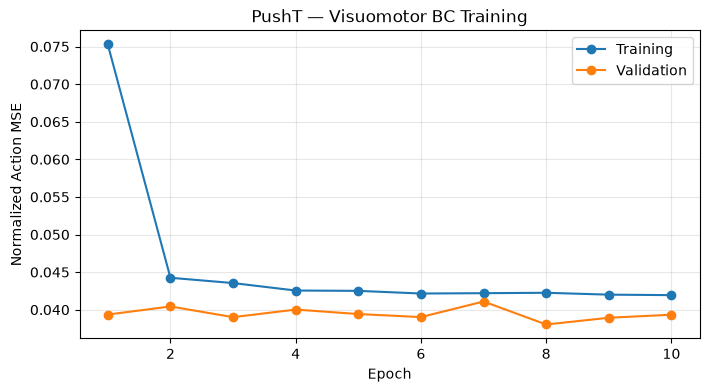

In [11]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, num_epochs + 1),
    train_losses,
    "o-",
    label="Training",
)

plt.plot(
    range(1, num_epochs + 1),
    val_losses,
    "o-",
    label="Validation",
)

plt.xlabel("Epoch")
plt.ylabel("Normalized Action MSE")
plt.title("PushT — Visuomotor BC Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 1.7 Visual Information Ablation

A low Behavior Cloning loss does not guarantee that the
policy has learned to use visual information.

We evaluate the same trained policy under two conditions:

1. Correct image-state pairs.
2. Randomly shuffled images with unchanged states.

The shuffled-image experiment breaks the correspondence
between visual observations and robot states.

If the policy relies on visual information, prediction
error should increase when images are shuffled.

This is a diagnostic experiment, not a definitive measure
of visual understanding.

In [12]:
bc_policy.eval()

correct_losses = []
shuffled_losses = []

rng = np.random.default_rng(42)

with torch.no_grad():
    for batch in val_loader:
        images, states, actions = prepare_batch(batch)

        # Correct image-state pairs
        predictions = bc_policy(images, states)
        correct_loss = F.mse_loss(predictions, actions)

        # Shuffle images, keeping states unchanged
        permutation = torch.as_tensor(
            rng.permutation(images.shape[0]),
            device=images.device,
        )

        shuffled_images = images[permutation]

        shuffled_predictions = bc_policy(
            shuffled_images,
            states,
        )

        shuffled_loss = F.mse_loss(
            shuffled_predictions,
            actions,
        )

        correct_losses.append(correct_loss.item() * len(images))
        shuffled_losses.append(shuffled_loss.item() * len(images))

correct_mse = sum(correct_losses) / len(val_dataset)
shuffled_mse = sum(shuffled_losses) / len(val_dataset)

print(f"Correct images MSE:  {correct_mse:.5f}")
print(f"Shuffled images MSE: {shuffled_mse:.5f}")
print(f"Difference:          {shuffled_mse - correct_mse:+.5f}")

Correct images MSE:  0.03933
Shuffled images MSE: 0.03933
Difference:          +0.00000


### 1.8 Identity Baseline

Our visual ablation suggests that the BC policy may rely
primarily on the agent state rather than visual observations.

In PushT, actions represent target positions in the same
coordinate system as the observed agent position.

We therefore compare our trained policy against a simple
identity baseline:

$$
\hat a_t = s_t
$$

If this baseline achieves a similar MSE, it suggests that
the policy may have learned a near-identity mapping rather
than meaningful visuomotor behavior.

This experiment illustrates why low imitation loss alone
is not sufficient to evaluate a robot learning policy.

In [13]:
bc_policy.eval()

total_bc_loss = 0.0
total_identity_loss = 0.0
total_samples = 0

with torch.no_grad():
    for batch in val_loader:
        images, states, actions = prepare_batch(batch)

        # Trained visuomotor BC
        predicted_actions = bc_policy(images, states)

        # Identity baseline in physical coordinates,
        # converted to normalized action coordinates
        states_physical = states * state_std_d + state_mean_d

        identity_actions = (
            states_physical - action_mean_d
        ) / action_std_d

        total_bc_loss += (
            F.mse_loss(predicted_actions, actions).item()
            * len(images)
        )

        total_identity_loss += (
            F.mse_loss(identity_actions, actions).item()
            * len(images)
        )

        total_samples += len(images)

print(f"Visuomotor BC MSE: {total_bc_loss / total_samples:.5f}")
print(f"Identity MSE:      {total_identity_loss / total_samples:.5f}")

Visuomotor BC MSE: 0.03933
Identity MSE:      0.03879


### 1.9 Closed-Loop Evaluation

Offline action prediction does not necessarily measure
the quality of a robot control policy.

Our visuomotor BC achieves an MSE similar to the identity
baseline, suggesting that it may have learned to predict
actions close to the current agent position.

We now evaluate the trained policy in the PushT simulator.

At each timestep:

1. Observe the current image and agent state.
2. Normalize the agent state.
3. Predict an action with the trained policy.
4. Denormalize the predicted action.
5. Execute the action in the environment.

We evaluate the resulting object manipulation using
the environment reward and success signals.

In [16]:
import torch
import torchvision.transforms.functional as TF

@torch.no_grad()
def predict_bc_action(model, image, state):
    model.eval()

    # HWC uint8 -> CHW float32, values in [0, 1]
    image = torch.as_tensor(
        image.copy(),
        dtype=torch.float32,
        device=device,
    )

    image = image.permute(2, 0, 1) / 255.0

    # Match training image resolution
    image = TF.resize(
        image,
        size=[96, 96],
        antialias=True,
    )

    image = image.unsqueeze(0)

    # Normalize agent state
    state = torch.as_tensor(
        state,
        dtype=torch.float32,
        device=device,
    ).reshape(1, 2)

    state = (state - state_mean_d) / state_std_d

    # Predict normalized action
    action_normalized = model(image, state)

    # Denormalize action
    action = (
        action_normalized * action_std_d + action_mean_d
    )

    return action[0].cpu().numpy().clip(0, 512)

In [17]:
import gymnasium as gym
import gym_pusht

env = gym.make(
    "gym_pusht/PushT-v0",
    obs_type="state",
    render_mode="rgb_array",
)

observation, info = env.reset(seed=42)

positions = [observation[:2].copy()]
rewards = []
frames = [env.render()]

for t in range(200):
    image = env.render()

    action = predict_bc_action(
        bc_policy,
        image,
        observation[:2],
    )

    observation, reward, terminated, truncated, info = env.step(action)

    positions.append(observation[:2].copy())
    rewards.append(reward)

    if t % 10 == 0:
        frames.append(env.render())

    if terminated or truncated:
        break

positions = np.array(positions)

print("Steps:", len(rewards))
print("Initial position:", positions[0])
print("Final position:", positions[-1])
print("Agent displacement:", np.linalg.norm(positions[-1] - positions[0]))
print("Maximum reward:", max(rewards))
print("Final reward:", rewards[-1])
print("Terminated:", terminated)
print("Truncated:", truncated)

Steps: 200
Initial position: [ 85. 359.]
Final position: [ 82.25603147 363.45606389]
Agent displacement: 5.233150938818585
Maximum reward: 0.05975931325587878
Final reward: 0.05975931325587878
Terminated: False
Truncated: False


## 2. Chunked Behavior Cloning

Standard Behavior Cloning predicts one action at a time:

$$
\hat a_t = \pi_\theta(I_t, s_t)
$$

Chunked Behavior Cloning predicts a sequence of future actions:

$$
\hat A_t =
[\hat a_t,\hat a_{t+1},\ldots,\hat a_{t+H-1}]
$$

where $H$ is the action horizon.

For PushT, each action represents a 2D position target.

With $H=8$:

$$
\hat A_t\in\mathbb R^{8\times2}
$$

The training objective becomes:

$$
\mathcal L_{\text{chunk}} =
\frac{1}{H}
\sum_{h=0}^{H-1}
\|\hat a_{t+h}-a_{t+h}\|_2^2
$$

Predicting multiple actions allows the policy to represent
short-term motion patterns.

However, deterministic MSE training can still average
different valid action sequences.

In [18]:
from torch.utils.data import Dataset

class PushTChunkDataset(Dataset):
    def __init__(self, dataset, episode_ids, horizon=8):
        self.dataset = dataset
        self.horizon = horizon
        self.samples = []

        for episode_id in episode_ids:
            info = dataset.meta.episodes[int(episode_id)]

            start = int(info["dataset_from_index"])
            end = int(info["dataset_to_index"])

            # Only chunks fully contained in an episode
            for t in range(start, end - horizon + 1):
                self.samples.append(t)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        t = self.samples[idx]

        sample = self.dataset[t]

        actions = torch.stack([
            self.dataset[t + h]["action"]
            for h in range(self.horizon)
        ])

        return {
            "image": sample["observation.image"],
            "state": sample["observation.state"],
            "actions": actions,
        }

In [19]:
H = 8

train_chunk_dataset = PushTChunkDataset(
    dataset,
    train_episode_ids,
    horizon=H,
)

val_chunk_dataset = PushTChunkDataset(
    dataset,
    val_episode_ids,
    horizon=H,
)

sample = train_chunk_dataset[0]

print("Training chunks:", len(train_chunk_dataset))
print("Validation chunks:", len(val_chunk_dataset))

print("Image:", sample["image"].shape)
print("State:", sample["state"].shape)
print("Action chunk:", sample["actions"].shape)

Training chunks: 19571
Validation chunks: 4637
Image: torch.Size([3, 96, 96])
State: torch.Size([2])
Action chunk: torch.Size([8, 2])


### 2.1 Chunked Visuomotor Policy

We extend the previous visuomotor BC architecture to predict
a sequence of future actions.

The visual encoder extracts image features:

$$
v_t = f_\theta(I_t)
$$

These features are concatenated with the normalized agent state:

$$
h_t = [v_t, \tilde{s}_t]
$$

The policy head predicts a complete action chunk:

$$
\hat{A}_t = g_\theta(h_t)
$$

where:

$$
\hat{A}_t \in \mathbb{R}^{H \times 2}
$$

Unlike autoregressive policies, all actions are predicted
simultaneously from the current observation.

We use the same CNN architecture as the single-action BC
baseline to make the comparison more meaningful.

In [20]:
class ChunkedVisuomotorBC(nn.Module):
    def __init__(self, horizon=8, visual_dim=128):
        super().__init__()

        self.horizon = horizon

        self.visual_encoder = VisualEncoder(
            feature_dim=visual_dim
        )

        self.policy_head = nn.Sequential(
            nn.Linear(visual_dim + 2, 256),
            nn.ReLU(),
            nn.Linear(256, 256),
            nn.ReLU(),
            nn.Linear(256, horizon * 2),
        )

    def forward(self, images, states):
        visual_features = self.visual_encoder(images)

        features = torch.cat(
            [visual_features, states],
            dim=-1,
        )

        actions = self.policy_head(features)

        return actions.reshape(-1, self.horizon, 2)

In [21]:
chunk_policy = ChunkedVisuomotorBC(
    horizon=H
).to(device)

sample = train_chunk_dataset[0]

image = sample["image"].unsqueeze(0).to(device)

state = sample["state"].unsqueeze(0).to(device)
state = (state - state_mean_d) / state_std_d

with torch.no_grad():
    predicted_chunk = chunk_policy(image, state)

print("Predicted chunk shape:", predicted_chunk.shape)

print(
    "Number of parameters:",
    sum(p.numel() for p in chunk_policy.parameters())
)

Predicted chunk shape: torch.Size([1, 8, 2])
Number of parameters: 460496


### 2.2 Training Chunked Behavior Cloning

We train the chunked policy using supervised imitation learning.

For each observation, the target is a sequence of $H=8$
future expert actions.

The training objective is:

$$
\mathcal{L}_{\text{chunk}} =
\frac{1}{BH D}
\sum_{b=1}^{B}
\sum_{h=1}^{H}
\sum_{d=1}^{D}
\left(
\hat{a}_{b,h,d} - a_{b,h,d}
\right)^2
$$

where $B$ is the batch size and $D=2$ is the action dimension.

We normalize states and actions using the same training-set
statistics as the single-action BC baseline.

This allows us to compare their validation losses on a
consistent scale.

In [22]:
# Cache action vectors only (not images)
all_actions = torch.stack([
    dataset[i]["action"]
    for i in range(len(dataset))
])

print("Cached actions:", all_actions.shape)

Cached actions: torch.Size([25650, 2])


In [23]:
class FastPushTChunkDataset(PushTChunkDataset):
    def __init__(self, dataset, episode_ids, actions, horizon=8):
        super().__init__(dataset, episode_ids, horizon)
        self.actions = actions

    def __getitem__(self, idx):
        t = self.samples[idx]
        sample = self.dataset[t]

        return {
            "image": sample["observation.image"],
            "state": sample["observation.state"],
            "actions": self.actions[t:t + self.horizon],
        }

In [24]:
train_chunk_dataset = FastPushTChunkDataset(
    dataset,
    train_episode_ids,
    all_actions,
    horizon=H,
)

val_chunk_dataset = FastPushTChunkDataset(
    dataset,
    val_episode_ids,
    all_actions,
    horizon=H,
)

train_chunk_loader = DataLoader(
    train_chunk_dataset,
    batch_size=64,
    shuffle=True,
    num_workers=0,
)

val_chunk_loader = DataLoader(
    val_chunk_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
)

In [25]:
def prepare_chunk_batch(batch):
    images = batch["image"].to(device)
    states = batch["state"].to(device)
    actions = batch["actions"].to(device)

    states = (states - state_mean_d) / state_std_d

    actions = (
        actions - action_mean_d.view(1, 1, 2)
    ) / action_std_d.view(1, 1, 2)

    return images, states, actions

In [26]:
batch = next(iter(train_chunk_loader))

images, states, actions = prepare_chunk_batch(batch)

print("Images:", images.shape)
print("States:", states.shape)
print("Actions:", actions.shape)

with torch.no_grad():
    predictions = chunk_policy(images, states)

print("Predictions:", predictions.shape)
print("Initial MSE:", F.mse_loss(predictions, actions).item())

Images: torch.Size([64, 3, 96, 96])
States: torch.Size([64, 2])
Actions: torch.Size([64, 8, 2])
Predictions: torch.Size([64, 8, 2])
Initial MSE: 0.9789953231811523


### 2.3 Training and Validation

We train the chunked visuomotor policy to predict eight
future actions from the current image and agent state.

The network is optimized using mean squared error between
predicted and expert action chunks.

We monitor training and validation losses to evaluate
generalization to held-out episodes.

Since the chunked model predicts multiple future actions,
its validation loss is not directly equivalent to the
single-action BC loss.

In [27]:
chunk_optimizer = torch.optim.Adam(
    chunk_policy.parameters(),
    lr=1e-3,
)

num_epochs = 10

chunk_train_losses = []
chunk_val_losses = []

for epoch in range(num_epochs):

    # Training
    chunk_policy.train()
    total_train_loss = 0.0

    for batch in train_chunk_loader:
        images, states, actions = prepare_chunk_batch(batch)

        predictions = chunk_policy(images, states)

        loss = F.mse_loss(predictions, actions)

        chunk_optimizer.zero_grad()
        loss.backward()
        chunk_optimizer.step()

        total_train_loss += loss.item() * images.size(0)

    avg_train_loss = total_train_loss / len(train_chunk_dataset)
    chunk_train_losses.append(avg_train_loss)

    # Validation
    chunk_policy.eval()
    total_val_loss = 0.0

    with torch.no_grad():
        for batch in val_chunk_loader:
            images, states, actions = prepare_chunk_batch(batch)

            predictions = chunk_policy(images, states)

            loss = F.mse_loss(predictions, actions)

            total_val_loss += loss.item() * images.size(0)

    avg_val_loss = total_val_loss / len(val_chunk_dataset)
    chunk_val_losses.append(avg_val_loss)

    print(
        f"Epoch {epoch + 1:02d}/{num_epochs} | "
        f"Train: {avg_train_loss:.5f} | "
        f"Val: {avg_val_loss:.5f}"
    )

Epoch 01/10 | Train: 0.24903 | Val: 0.19138
Epoch 02/10 | Train: 0.20527 | Val: 0.18640
Epoch 03/10 | Train: 0.20245 | Val: 0.18785
Epoch 04/10 | Train: 0.18562 | Val: 0.15008
Epoch 05/10 | Train: 0.14041 | Val: 0.12191
Epoch 06/10 | Train: 0.12367 | Val: 0.11937
Epoch 07/10 | Train: 0.11460 | Val: 0.11312
Epoch 08/10 | Train: 0.10641 | Val: 0.11105
Epoch 09/10 | Train: 0.10096 | Val: 0.10788
Epoch 10/10 | Train: 0.09639 | Val: 0.10424


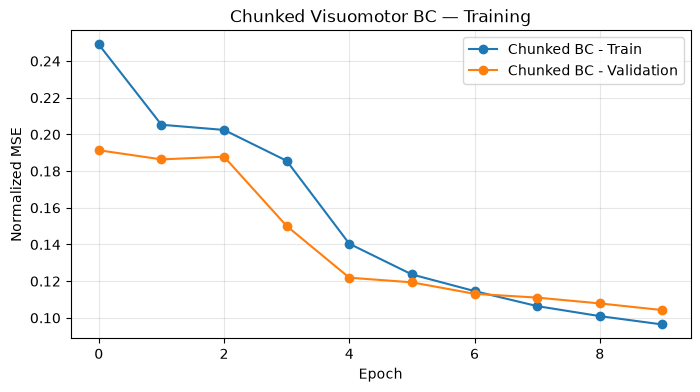

In [28]:
plt.figure(figsize=(8, 4))

plt.plot(
    chunk_train_losses,
    label="Chunked BC - Train",
    marker="o",
)

plt.plot(
    chunk_val_losses,
    label="Chunked BC - Validation",
    marker="o",
)

plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("Chunked Visuomotor BC — Training")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 2.4 Does Chunked BC Use Visual Information?

A low validation MSE does not guarantee that the policy
uses visual observations.

We evaluate three configurations:

- **Correct images:** the trained policy receives the
  original image and agent state.
- **Shuffled images:** the policy receives an image from
  another sample while keeping the original state.
- **Identity baseline:** the current agent position is
  repeated across the entire action horizon.

The identity baseline predicts:

$$
\hat{A}_t =
[s_t,s_t,\ldots,s_t]
\in \mathbb{R}^{H\times2}
$$

If shuffling images substantially increases prediction
error, the model is sensitive to visual information.

If the model performs similarly to the identity baseline,
it may have learned to predict nearly stationary targets.

These are diagnostic tests: image shuffling creates
observation combinations that may not occur naturally.

In [30]:
chunk_policy.eval()

total_correct = 0.0
total_shuffled = 0.0
total_identity = 0.0
total_samples = 0

rng = np.random.default_rng(42)

with torch.no_grad():
    for batch in val_chunk_loader:
        images, states, actions = prepare_chunk_batch(batch)

        # 1. Correct observations
        predictions = chunk_policy(images, states)

        # 2. Shuffled images, unchanged states
        permutation = torch.as_tensor(
            rng.permutation(len(images)),
            device=images.device,
        )

        shuffled_predictions = chunk_policy(
            images[permutation],
            states,
        )

        # 3. Identity baseline
        # Recover physical agent position
        states_physical = (
            states * state_std_d + state_mean_d
        )

        # Normalize with action statistics
        identity_action = (
            states_physical - action_mean_d
        ) / action_std_d

        # Repeat current position over the horizon
        identity_chunk = identity_action.unsqueeze(1).expand(
            -1, H, -1
        )

        batch_size = len(images)

        total_correct += (
            F.mse_loss(predictions, actions).item()
            * batch_size
        )

        total_shuffled += (
            F.mse_loss(shuffled_predictions, actions).item()
            * batch_size
        )

        total_identity += (
            F.mse_loss(identity_chunk, actions).item()
            * batch_size
        )

        total_samples += batch_size

correct_mse = total_correct / total_samples
shuffled_mse = total_shuffled / total_samples
identity_mse = total_identity / total_samples

print(f"Chunked BC MSE:       {correct_mse:.5f}")
print(f"Shuffled images MSE:  {shuffled_mse:.5f}")
print(f"Identity baseline:    {identity_mse:.5f}")
print(f"Visual sensitivity:   {shuffled_mse - correct_mse:+.5f}")

Chunked BC MSE:       0.10424
Shuffled images MSE:  0.28219
Identity baseline:    0.20223
Visual sensitivity:   +0.17795


### 2.5 Visualizing Predicted Action Chunks

The visual ablation indicates that Chunked BC uses image
information and outperforms the identity baseline.

We now inspect the predicted action sequences.

For a validation observation, we visualize:

- The current agent position.
- The eight future expert action targets.
- The eight action targets predicted by Chunked BC.

All positions are shown in the original PushT coordinate
system (0–512).

This helps us understand whether the model predicts
meaningful motion or nearly stationary action sequences.

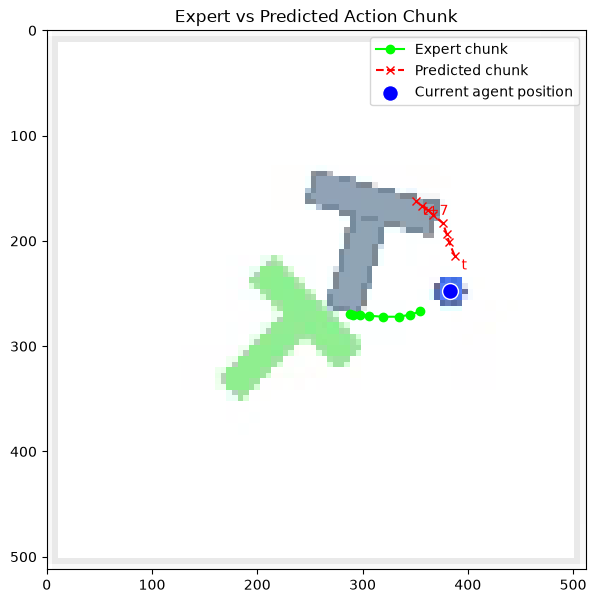

In [31]:
chunk_policy.eval()

# Choose a validation sample
sample = val_chunk_dataset[100]

image = sample["image"]
state = sample["state"]
expert_chunk = sample["actions"].numpy()

# Normalize state
state_normalized = (
    state.to(device) - state_mean_d
) / state_std_d

# Predict chunk
with torch.no_grad():
    predicted_normalized = chunk_policy(
        image.unsqueeze(0).to(device),
        state_normalized.unsqueeze(0),
    )

# Denormalize predicted actions
predicted_chunk = (
    predicted_normalized[0] * action_std_d + action_mean_d
).cpu().numpy()

agent_position = state.numpy()

# Display
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    image.permute(1, 2, 0),
    extent=[0, 512, 512, 0],
)

ax.plot(
    expert_chunk[:, 0],
    expert_chunk[:, 1],
    "o-",
    color="lime",
    label="Expert chunk",
)

ax.plot(
    predicted_chunk[:, 0],
    predicted_chunk[:, 1],
    "x--",
    color="red",
    label="Predicted chunk",
)

ax.scatter(
    agent_position[0],
    agent_position[1],
    s=130,
    color="blue",
    edgecolors="white",
    label="Current agent position",
    zorder=5,
)

# Highlight first and last predicted targets
ax.annotate(
    "t",
    predicted_chunk[0],
    xytext=(5, -10),
    textcoords="offset points",
    color="red",
)

ax.annotate(
    "t+7",
    predicted_chunk[-1],
    xytext=(5, -10),
    textcoords="offset points",
    color="red",
)

ax.set_xlim(0, 512)
ax.set_ylim(512, 0)
ax.set_aspect("equal")
ax.set_title("Expert vs Predicted Action Chunk")
ax.legend()
plt.show()

### 2.6 Closed-Loop Evaluation with Open-Loop Action Chunks

We evaluate Chunked BC in the PushT environment.

At each planning step:

1. Observe the current image and agent position.
2. Predict an action chunk of length $H=8$.
3. Execute the eight predicted actions sequentially.
4. Observe the new state and replan.

Although the overall rollout is closed-loop, each individual
action chunk is executed open-loop.

We measure the maximum reward, final reward, and agent
displacement to compare against single-action BC.

In [32]:
@torch.no_grad()
def predict_action_chunk(model, image, state):
    model.eval()

    image = torch.as_tensor(
        image.copy(),
        dtype=torch.float32,
        device=device,
    ).permute(2, 0, 1) / 255.0

    image = TF.resize(
        image,
        [96, 96],
        antialias=True,
    ).unsqueeze(0)

    state = torch.as_tensor(
        state,
        dtype=torch.float32,
        device=device,
    ).reshape(1, 2)

    state = (state - state_mean_d) / state_std_d

    predicted = model(image, state)[0]

    actions = predicted * action_std_d + action_mean_d

    return actions.cpu().numpy().clip(0, 512)

In [33]:
env = gym.make(
    "gym_pusht/PushT-v0",
    obs_type="state",
    render_mode="rgb_array",
)

observation, info = env.reset(seed=42)

positions = [observation[:2].copy()]
rewards = []
frames = [env.render()]

terminated = False
truncated = False

for t in range(0, 200, H):

    image = env.render()

    chunk = predict_action_chunk(
        chunk_policy,
        image,
        observation[:2],
    )

    for action in chunk:
        observation, reward, terminated, truncated, info = env.step(
            action.astype(np.float32)
        )

        positions.append(observation[:2].copy())
        rewards.append(reward)

        if len(rewards) % 10 == 0:
            frames.append(env.render())

        if terminated or truncated:
            break

    if terminated or truncated:
        break

positions = np.array(positions)

print("Steps:", len(rewards))
print("Initial position:", positions[0])
print("Final position:", positions[-1])
print(
    "Agent displacement:",
    np.linalg.norm(positions[-1] - positions[0])
)
print("Maximum reward:", max(rewards))
print("Final reward:", rewards[-1])
print("Terminated:", terminated)
print("Truncated:", truncated)

Steps: 200
Initial position: [ 85. 359.]
Final position: [ 55.46657122 359.82415417]
Agent displacement: 29.54492588233166
Maximum reward: 0.4449318242153215
Final reward: 0.0
Terminated: False
Truncated: False


### 2.7 Inspecting Closed-Loop Behavior

Chunked BC achieves a substantially higher maximum reward
than single-action BC, but the final reward drops to zero.

We inspect the rollout to understand when the policy makes
progress and when it loses it.

We visualize:

- The reward over time.
- Selected frames from the rollout.
- The agent trajectory.

This allows us to distinguish temporary task progress
from sustained manipulation success.

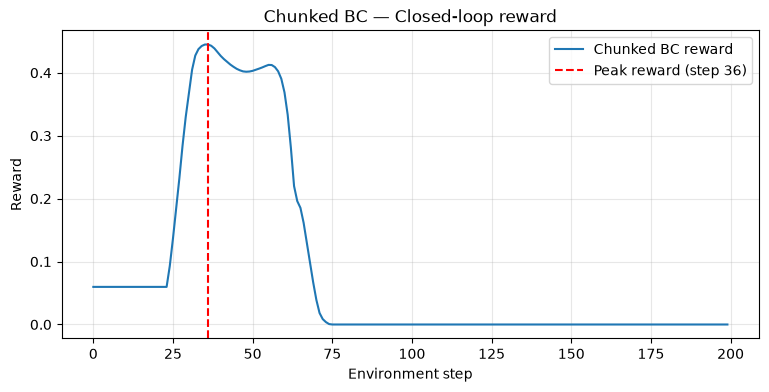

Peak reward: 0.4449318242153215
Peak step: 36


In [34]:
peak_step = int(np.argmax(rewards))

fig, ax = plt.subplots(figsize=(9, 4))

ax.plot(rewards, label="Chunked BC reward")
ax.axvline(
    peak_step,
    color="red",
    linestyle="--",
    label=f"Peak reward (step {peak_step})",
)

ax.set_xlabel("Environment step")
ax.set_ylabel("Reward")
ax.set_title("Chunked BC — Closed-loop reward")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

print("Peak reward:", rewards[peak_step])
print("Peak step:", peak_step)

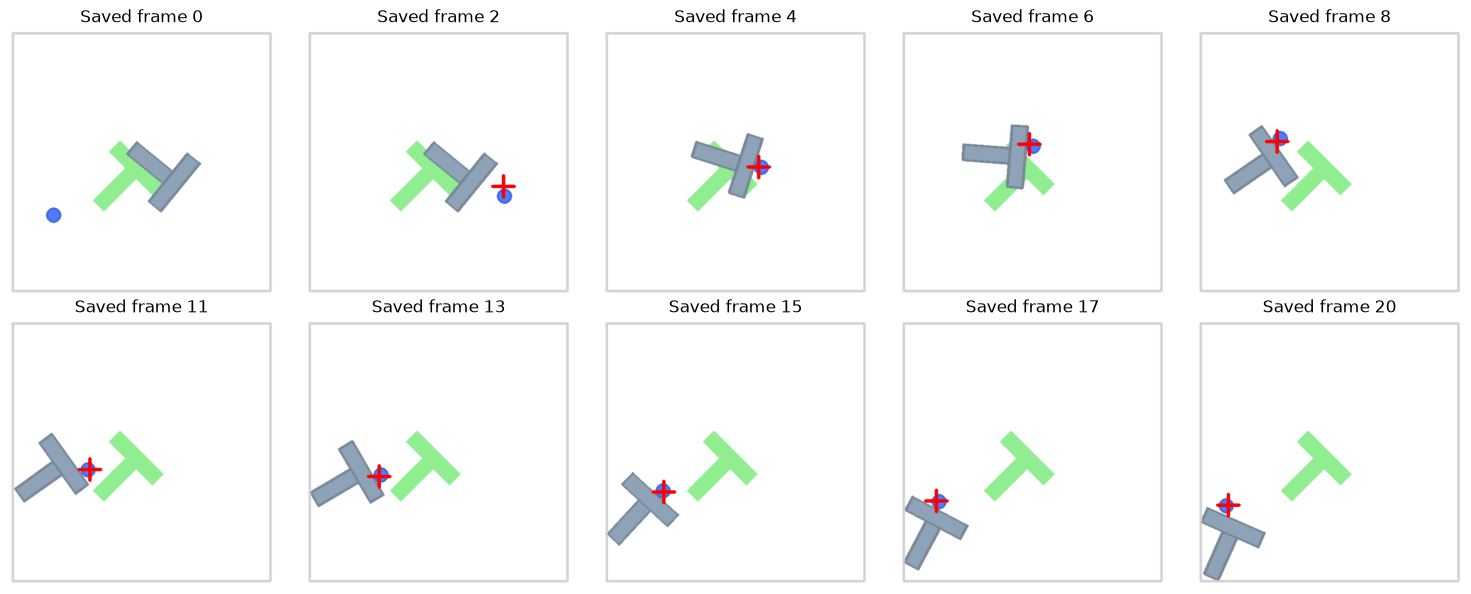

In [35]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

frame_indices = np.linspace(
    0,
    len(frames) - 1,
    10,
    dtype=int,
)

for ax, idx in zip(axes.flat, frame_indices):
    ax.imshow(frames[idx])
    ax.set_title(f"Saved frame {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

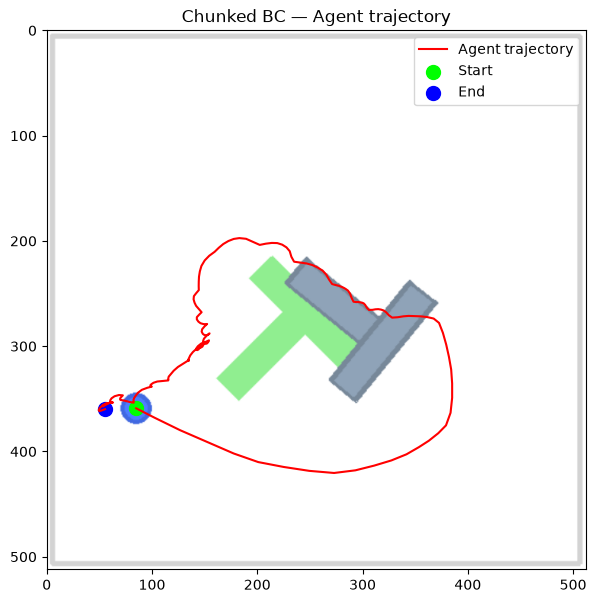

In [36]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    frames[0],
    extent=[0, 512, 512, 0],
)

ax.plot(
    positions[:, 0],
    positions[:, 1],
    color="red",
    linewidth=1.5,
    label="Agent trajectory",
)

ax.scatter(
    *positions[0],
    color="lime",
    s=100,
    label="Start",
)

ax.scatter(
    *positions[-1],
    color="blue",
    s=100,
    label="End",
)

ax.set_xlim(0, 512)
ax.set_ylim(512, 0)
ax.set_aspect("equal")
ax.set_title("Chunked BC — Agent trajectory")
ax.legend()

plt.show()

### 2.8 Receding-Horizon Execution

We now compare two execution strategies using the same
trained Chunked BC model.

**Open-loop execution:** predict $H$ actions and execute
all of them before replanning.

**Receding-horizon execution:** predict $H$ actions,
execute only the first action, and replan at every timestep.

$$
a_t = \pi_\theta(I_t,s_t)[0]
$$

This experiment isolates the effect of execution strategy
without changing the policy architecture or its weights.

Receding-horizon control provides more frequent feedback,
but it does not guarantee better performance.

In [37]:
env_rh = gym.make(
    "gym_pusht/PushT-v0",
    obs_type="state",
    render_mode="rgb_array",
)

observation, info = env_rh.reset(seed=42)

rh_positions = [observation[:2].copy()]
rh_rewards = []
rh_frames = [env_rh.render()]

terminated = False
truncated = False

for t in range(200):

    image = env_rh.render()

    # Predict H actions, execute only the first
    chunk = predict_action_chunk(
        chunk_policy,
        image,
        observation[:2],
    )

    action = chunk[0].astype(np.float32)

    observation, reward, terminated, truncated, info = (
        env_rh.step(action)
    )

    rh_positions.append(observation[:2].copy())
    rh_rewards.append(reward)

    if (t + 1) % 10 == 0:
        rh_frames.append(env_rh.render())

    if terminated or truncated:
        break

rh_positions = np.array(rh_positions)

print("Steps:", len(rh_rewards))
print("Maximum reward:", max(rh_rewards))
print("Final reward:", rh_rewards[-1])
print("Peak step:", np.argmax(rh_rewards))
print("Terminated:", terminated)
print("Truncated:", truncated)

env_rh.close()

Steps: 200
Maximum reward: 0.3450388250784556
Final reward: 0.27268439824863416
Peak step: 55
Terminated: False
Truncated: False


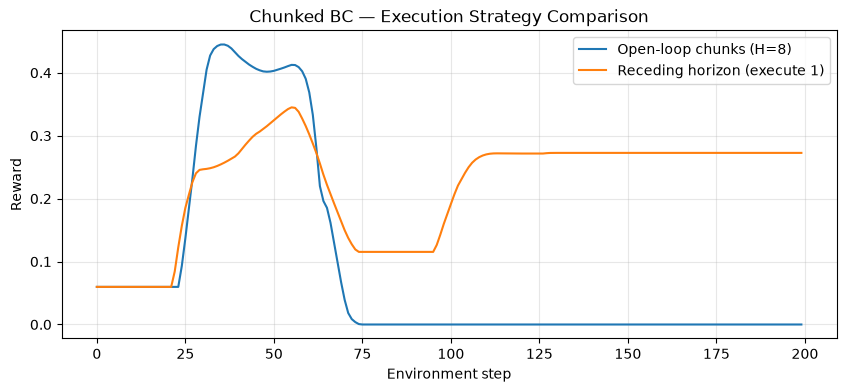

In [38]:
plt.figure(figsize=(10, 4))

plt.plot(
    rewards,
    label="Open-loop chunks (H=8)",
)

plt.plot(
    rh_rewards,
    label="Receding horizon (execute 1)",
)

plt.xlabel("Environment step")
plt.ylabel("Reward")
plt.title("Chunked BC — Execution Strategy Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

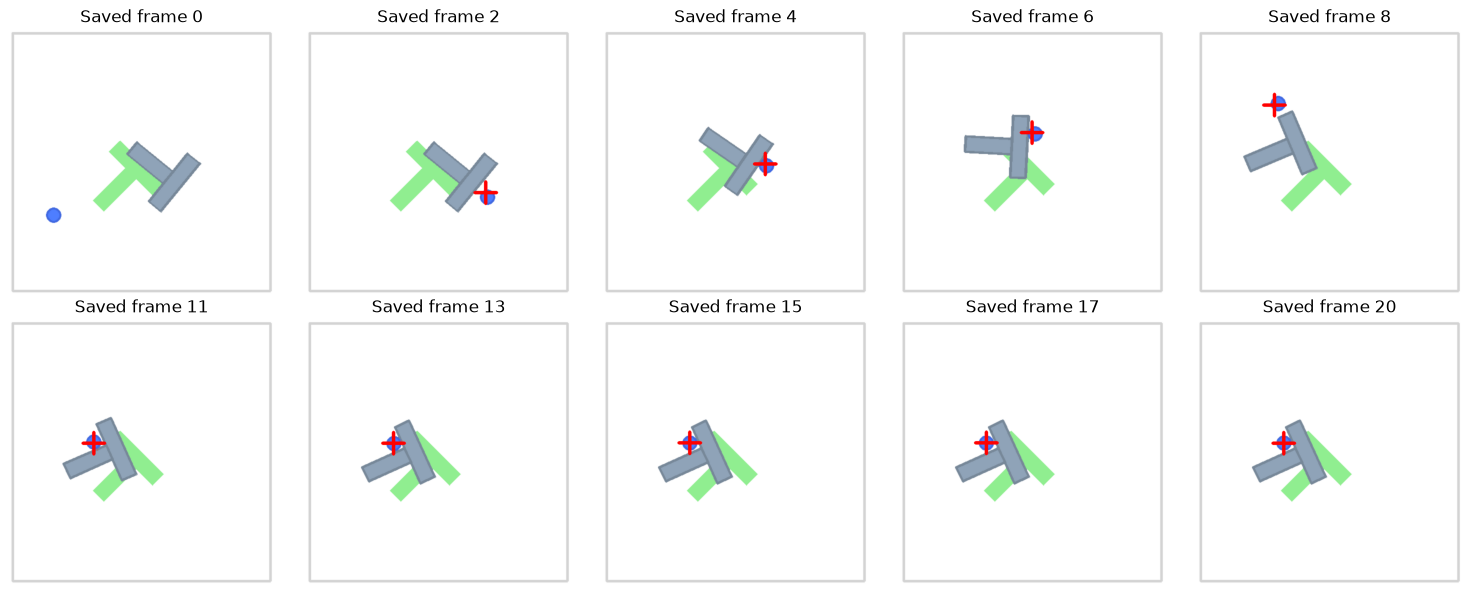

In [40]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

frame_indices = np.linspace(
    0,
    len(rh_frames) - 1,
    10,
    dtype=int,
)

for ax, idx in zip(axes.flat, frame_indices):
    ax.imshow(rh_frames[idx])
    ax.set_title(f"Saved frame {idx}")
    ax.axis("off")

plt.tight_layout()
plt.show()

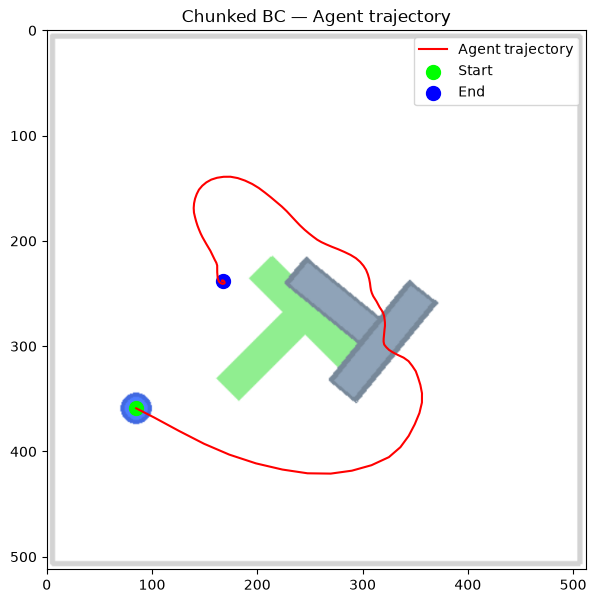

In [41]:
fig, ax = plt.subplots(figsize=(7, 7))

ax.imshow(
    rh_frames[0],
    extent=[0, 512, 512, 0],
)

ax.plot(
    rh_positions[:, 0],
    rh_positions[:, 1],
    color="red",
    linewidth=1.5,
    label="Agent trajectory",
)

ax.scatter(
    *rh_positions[0],
    color="lime",
    s=100,
    label="Start",
)

ax.scatter(
    *rh_positions[-1],
    color="blue",
    s=100,
    label="End",
)

ax.set_xlim(0, 512)
ax.set_ylim(512, 0)
ax.set_aspect("equal")
ax.set_title("Chunked BC — Agent trajectory")
ax.legend()

plt.show()

### 2.9 Temporal Ensembling

At each timestep, the policy predicts a new action chunk.

Multiple chunks may contain predictions for the same future
timestep. Temporal ensembling combines these overlapping
predictions using a weighted average:

$$
a_t = \frac{\sum_i w_i \hat a_t^{(i)}}{\sum_i w_i}
$$

We use exponential weights, giving more importance to
recent predictions.

This allows us to update the plan at every timestep while
using information from previous action chunks.

In [42]:
env_te = gym.make(
    "gym_pusht/PushT-v0",
    obs_type="state",
    render_mode="rgb_array",
)

obs, info = env_te.reset(seed=42)

te_rewards = []
te_frames = [env_te.render()]

# Each entry: (prediction timestep, predicted chunk)
chunk_history = []

decay = 0.1  # More weight to recent predictions

for t in range(200):
    chunk = predict_action_chunk(
        chunk_policy,
        env_te.render(),
        obs[:2],
    )

    chunk_history.append((t, chunk))

    # Keep only chunks that still predict an action for time t
    chunk_history = [
        (start, actions)
        for start, actions in chunk_history
        if t - start < H
    ]

    candidates = []
    weights = []

    for start, actions in chunk_history:
        age = t - start

        candidates.append(actions[age])
        weights.append(np.exp(-decay * age))

    action = np.average(
        np.stack(candidates),
        axis=0,
        weights=weights,
    ).astype(np.float32)

    obs, reward, terminated, truncated, info = env_te.step(action)

    te_rewards.append(reward)

    if (t + 1) % 10 == 0:
        te_frames.append(env_te.render())

    if terminated or truncated:
        break

env_te.close()

print(f"Maximum reward: {max(te_rewards):.4f}")
print(f"Final reward:   {te_rewards[-1]:.4f}")
print(f"Peak step:      {np.argmax(te_rewards)}")

Maximum reward: 0.4393
Final reward:   0.0000
Peak step:      35


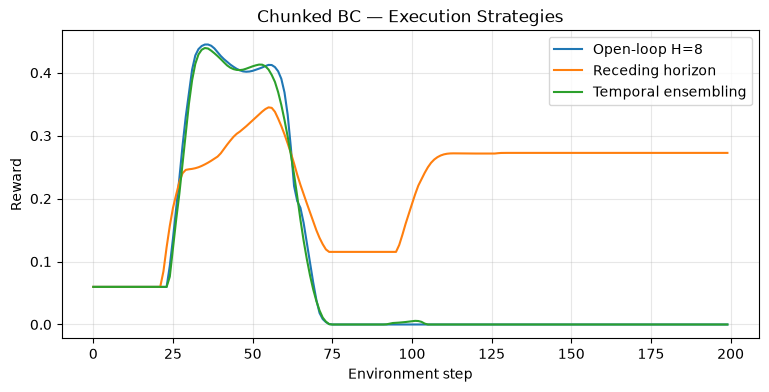

In [43]:
plt.figure(figsize=(9, 4))

plt.plot(rewards, label="Open-loop H=8")
plt.plot(rh_rewards, label="Receding horizon")
plt.plot(te_rewards, label="Temporal ensembling")

plt.xlabel("Environment step")
plt.ylabel("Reward")
plt.title("Chunked BC — Execution Strategies")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 3. Mini-ACT: Action Chunking with Transformers

Action Chunking with Transformers (ACT) combines:

- A visual encoder for image observations.
- A CVAE encoder that learns a latent representation of expert action chunks.
- A Transformer decoder that predicts future actions.
- A reconstruction loss and KL regularization.

During training, the latent variable is inferred from
the demonstrated action chunk.

During inference, the expert actions are unavailable,
so we use the prior mean $z=0$.

Our Mini-ACT predicts $H=8$ future 2D position targets.

In [44]:
class ACTLatentEncoder(nn.Module):
    def __init__(self, horizon=8, hidden_dim=128, latent_dim=32):
        super().__init__()

        self.horizon = horizon

        self.input_proj = nn.Linear(2, hidden_dim)
        self.action_proj = nn.Linear(2, hidden_dim)

        self.cls_token = nn.Parameter(
            torch.zeros(1, 1, hidden_dim)
        )

        self.pos_embedding = nn.Parameter(
            torch.randn(1, horizon + 2, hidden_dim) * 0.02
        )

        encoder_layer = nn.TransformerEncoderLayer(
            d_model=hidden_dim,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True,
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2,
            enable_nested_tensor=False,
        )

        self.latent_head = nn.Linear(hidden_dim, latent_dim * 2)

    def forward(self, states, actions):
        batch_size = states.shape[0]

        cls = self.cls_token.expand(batch_size, -1, -1)
        state_token = self.input_proj(states).unsqueeze(1)
        action_tokens = self.action_proj(actions)

        tokens = torch.cat(
            [cls, state_token, action_tokens],
            dim=1,
        )

        tokens = tokens + self.pos_embedding

        encoded = self.transformer(tokens)

        mu, logvar = self.latent_head(
            encoded[:, 0]
        ).chunk(2, dim=-1)

        return mu, logvar

In [45]:
latent_encoder = ACTLatentEncoder(
    horizon=H,
    hidden_dim=128,
    latent_dim=32,
).to(device)

batch = next(iter(train_chunk_loader))
images, states, actions = prepare_chunk_batch(batch)

mu, logvar = latent_encoder(states, actions)

print("States:", states.shape)
print("Actions:", actions.shape)
print("Latent mean:", mu.shape)
print("Latent logvar:", logvar.shape)

States: torch.Size([64, 2])
Actions: torch.Size([64, 8, 2])
Latent mean: torch.Size([64, 32])
Latent logvar: torch.Size([64, 32])


### 3.1 Transformer Action Decoder

Mini-ACT uses a Transformer decoder to predict an action chunk.

The decoder receives:

- Visual features extracted from the current image.
- The normalized robot state.
- A latent variable $z$ inferred by the CVAE encoder.

We use $H=8$ learned action queries:

$$
Q \in \mathbb{R}^{H \times d}
$$

The Transformer decoder attends to observation tokens:

$$
Y = \operatorname{TransformerDecoder}(Q, M)
$$

where $M$ contains the visual, state, and latent tokens.

Each output token is projected to a 2D action:

$$
\hat A_t \in \mathbb{R}^{8 \times 2}
$$

This is a simplified ACT architecture: our visual encoder
produces a single global feature token rather than a grid
of spatial visual tokens.

In [46]:
class ACTActionDecoder(nn.Module):
    def __init__(
        self,
        horizon=8,
        hidden_dim=128,
        latent_dim=32,
    ):
        super().__init__()

        self.horizon = horizon

        self.visual_encoder = VisualEncoder(
            feature_dim=hidden_dim
        )

        self.state_proj = nn.Linear(2, hidden_dim)
        self.latent_proj = nn.Linear(latent_dim, hidden_dim)

        # One learned query per future action
        self.action_queries = nn.Parameter(
            torch.randn(1, horizon, hidden_dim) * 0.02
        )

        # Identify the three observation token types
        self.memory_pos = nn.Parameter(
            torch.randn(1, 3, hidden_dim) * 0.02
        )

        decoder_layer = nn.TransformerDecoderLayer(
            d_model=hidden_dim,
            nhead=4,
            dim_feedforward=256,
            dropout=0.1,
            batch_first=True,
        )

        self.transformer = nn.TransformerDecoder(
            decoder_layer,
            num_layers=2,
        )

        self.action_head = nn.Linear(hidden_dim, 2)

    def forward(self, images, states, z):
        batch_size = images.shape[0]

        # Observation tokens
        visual_token = self.visual_encoder(images).unsqueeze(1)
        state_token = self.state_proj(states).unsqueeze(1)
        latent_token = self.latent_proj(z).unsqueeze(1)

        memory = torch.cat(
            [visual_token, state_token, latent_token],
            dim=1,
        )

        memory = memory + self.memory_pos

        # Learned action queries
        queries = self.action_queries.expand(
            batch_size, -1, -1
        )

        decoded = self.transformer(
            tgt=queries,
            memory=memory,
        )

        return self.action_head(decoded)

In [47]:
class MiniACT(nn.Module):
    def __init__(
        self,
        horizon=8,
        hidden_dim=128,
        latent_dim=32,
    ):
        super().__init__()

        self.latent_dim = latent_dim

        self.latent_encoder = ACTLatentEncoder(
            horizon=horizon,
            hidden_dim=hidden_dim,
            latent_dim=latent_dim,
        )

        self.action_decoder = ACTActionDecoder(
            horizon=horizon,
            hidden_dim=hidden_dim,
            latent_dim=latent_dim,
        )

    def forward(self, images, states, actions=None):

        if actions is not None:
            mu, logvar = self.latent_encoder(
                states, actions
            )

            std = torch.exp(0.5 * logvar)
            z = mu + std * torch.randn_like(std)

        else:
            batch_size = images.shape[0]

            z = torch.zeros(
                batch_size,
                self.latent_dim,
                device=images.device,
            )

            mu, logvar = None, None

        predictions = self.action_decoder(
            images, states, z
        )

        return predictions, mu, logvar

In [48]:
mini_act = MiniACT(
    horizon=H,
    hidden_dim=128,
    latent_dim=32,
).to(device)

batch = next(iter(train_chunk_loader))
images, states, actions = prepare_chunk_batch(batch)

mini_act.eval()

with torch.no_grad():
    # Training mode: expert actions available
    predictions, mu, logvar = mini_act(
        images, states, actions
    )

    # Inference mode: no expert actions
    inference_predictions, _, _ = mini_act(
        images, states
    )

print("Training predictions:", predictions.shape)
print("Inference predictions:", inference_predictions.shape)
print("Latent mean:", mu.shape)
print("Latent logvar:", logvar.shape)

print(
    "Parameters:",
    sum(p.numel() for p in mini_act.parameters())
)

Training predictions: torch.Size([64, 8, 2])
Inference predictions: torch.Size([64, 8, 2])
Latent mean: torch.Size([64, 32])
Latent logvar: torch.Size([64, 32])
Parameters: 1036290


### 3.2 Mini-ACT Training Objective

Mini-ACT is trained using a conditional variational
autoencoder objective.

The reconstruction term measures the difference between
predicted and demonstrated action chunks:

$$
\mathcal{L}_{rec} = \|\hat A_t-A_t\|_1
$$

The KL divergence regularizes the latent distribution:

$$
\mathcal{L}_{KL} =
-\frac{1}{2}\sum_j
(1+\log\sigma_j^2-\mu_j^2-\sigma_j^2)
$$

The total objective is:

$$
\mathcal{L} = \mathcal{L}_{rec}+\beta\mathcal{L}_{KL}
$$

We monitor reconstruction and KL losses separately.

During inference, the latent encoder is not used and
the decoder receives $z=0$.

In [49]:
def mini_act_loss(predictions, actions, mu, logvar, beta=0.001):
    reconstruction = F.l1_loss(predictions, actions)

    # Sum over latent dimensions, mean over batch
    kl = -0.5 * (
        1 + logvar - mu.pow(2) - logvar.exp()
    ).sum(dim=-1).mean()

    total = reconstruction + beta * kl

    return total, reconstruction, kl

In [50]:
act_optimizer = torch.optim.Adam(
    mini_act.parameters(),
    lr=1e-4,
)

num_epochs = 10
beta = 0.001

act_train_losses = []
act_val_losses = []
act_rec_losses = []
act_kl_losses = []

for epoch in range(num_epochs):

    mini_act.train()
    train_total = train_rec = train_kl = 0.0

    for batch in train_chunk_loader:
        images, states, actions = prepare_chunk_batch(batch)

        predictions, mu, logvar = mini_act(
            images, states, actions
        )

        loss, rec, kl = mini_act_loss(
            predictions, actions, mu, logvar, beta
        )

        act_optimizer.zero_grad()
        loss.backward()
        act_optimizer.step()

        n = images.size(0)
        train_total += loss.item() * n
        train_rec += rec.item() * n
        train_kl += kl.item() * n

    act_train_losses.append(train_total / len(train_chunk_dataset))
    act_rec_losses.append(train_rec / len(train_chunk_dataset))
    act_kl_losses.append(train_kl / len(train_chunk_dataset))

    # Validation with posterior sampling, as in training
    mini_act.eval()
    val_total = 0.0

    with torch.no_grad():
        for batch in val_chunk_loader:
            images, states, actions = prepare_chunk_batch(batch)

            predictions, mu, logvar = mini_act(
                images, states, actions
            )

            loss, _, _ = mini_act_loss(
                predictions, actions, mu, logvar, beta
            )

            val_total += loss.item() * images.size(0)

    act_val_losses.append(val_total / len(val_chunk_dataset))

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {act_train_losses[-1]:.4f} | "
        f"Val: {act_val_losses[-1]:.4f} | "
        f"Rec: {act_rec_losses[-1]:.4f} | "
        f"KL: {act_kl_losses[-1]:.4f}"
    )

Epoch 01 | Train: 0.2563 | Val: 0.1294 | Rec: 0.2409 | KL: 15.3774
Epoch 02 | Train: 0.1625 | Val: 0.1187 | Rec: 0.1426 | KL: 19.8956
Epoch 03 | Train: 0.1472 | Val: 0.1085 | Rec: 0.1275 | KL: 19.6416
Epoch 04 | Train: 0.1371 | Val: 0.1051 | Rec: 0.1190 | KL: 18.1211
Epoch 05 | Train: 0.1285 | Val: 0.1008 | Rec: 0.1122 | KL: 16.2468
Epoch 06 | Train: 0.1235 | Val: 0.0976 | Rec: 0.1086 | KL: 14.9744
Epoch 07 | Train: 0.1194 | Val: 0.1057 | Rec: 0.1047 | KL: 14.7014
Epoch 08 | Train: 0.1170 | Val: 0.0959 | Rec: 0.1025 | KL: 14.4953
Epoch 09 | Train: 0.1140 | Val: 0.0965 | Rec: 0.0997 | KL: 14.3022
Epoch 10 | Train: 0.1121 | Val: 0.0952 | Rec: 0.0979 | KL: 14.1376


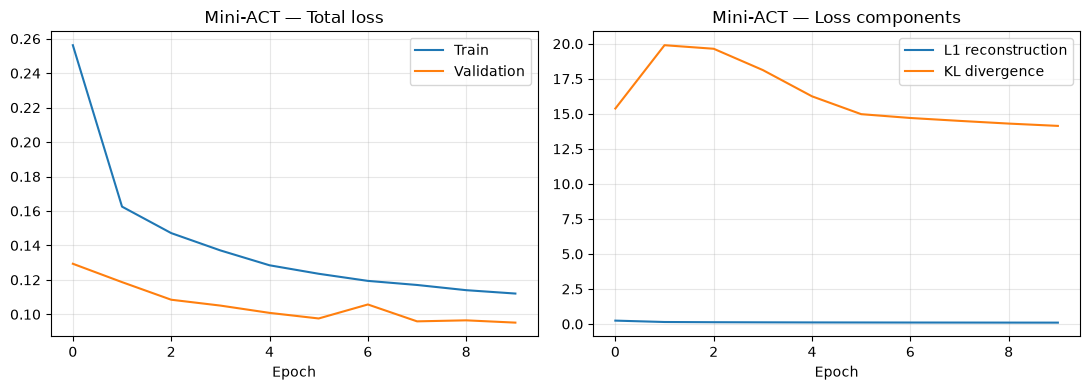

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(act_train_losses, label="Train")
axes[0].plot(act_val_losses, label="Validation")
axes[0].set_title("Mini-ACT — Total loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(act_rec_losses, label="L1 reconstruction")
axes[1].plot(act_kl_losses, label="KL divergence")
axes[1].set_title("Mini-ACT — Loss components")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 3.3 Posterior vs Prior Evaluation

During training, Mini-ACT uses the expert action chunk
to infer a latent variable.

During inference, expert future actions are unavailable.
We therefore use the prior mean $z=0$.

We compare:

- Posterior reconstruction using expert actions.
- Prior prediction with $z=0$.
- Prior prediction with shuffled images.

All results are measured using normalized action MSE.

A large gap between posterior and prior performance
indicates that the decoder relies heavily on latent
information unavailable at inference time.

In [52]:
mini_act.eval()

posterior_mse = 0.0
prior_mse = 0.0
shuffled_mse = 0.0
total_samples = 0

rng = np.random.default_rng(42)

with torch.no_grad():
    for batch in val_chunk_loader:
        images, states, actions = prepare_chunk_batch(batch)
        n = images.size(0)

        # Posterior: expert actions available
        posterior_pred, _, _ = mini_act(
            images, states, actions
        )

        # Prior: z = 0, no expert actions
        prior_pred, _, _ = mini_act(
            images, states
        )

        # Prior with shuffled images
        permutation = torch.as_tensor(
            rng.permutation(n),
            device=images.device,
        )

        shuffled_pred, _, _ = mini_act(
            images[permutation],
            states,
        )

        posterior_mse += F.mse_loss(
            posterior_pred, actions
        ).item() * n

        prior_mse += F.mse_loss(
            prior_pred, actions
        ).item() * n

        shuffled_mse += F.mse_loss(
            shuffled_pred, actions
        ).item() * n

        total_samples += n

posterior_mse /= total_samples
prior_mse /= total_samples
shuffled_mse /= total_samples

print(f"Mini-ACT posterior MSE: {posterior_mse:.5f}")
print(f"Mini-ACT prior MSE:     {prior_mse:.5f}")
print(f"Shuffled images MSE:   {shuffled_mse:.5f}")
print(f"Visual sensitivity:    {shuffled_mse - prior_mse:+.5f}")
print(f"Chunked BC MSE:        {correct_mse:.5f}")

Mini-ACT posterior MSE: 0.01352
Mini-ACT prior MSE:     0.24528
Shuffled images MSE:   0.25199
Visual sensitivity:    +0.00671
Chunked BC MSE:        0.10424


### 3.4 Mini-ACT Closed-Loop Evaluation

We evaluate Mini-ACT using the prior mean $z=0$.

At each timestep, the policy predicts an action chunk from
the current image and agent state.

We execute only the first predicted action and replan at
the next timestep.

This evaluation measures the actual inference-time policy,
without access to expert action chunks.

In [53]:
@torch.no_grad()
def predict_mini_act_chunk(model, image, state):
    model.eval()

    image = torch.as_tensor(
        image.copy(),
        dtype=torch.float32,
        device=device,
    ).permute(2, 0, 1) / 255.0

    image = TF.resize(
        image, [96, 96], antialias=True
    ).unsqueeze(0)

    state = torch.as_tensor(
        state,
        dtype=torch.float32,
        device=device,
    ).reshape(1, 2)

    state = (state - state_mean_d) / state_std_d

    # No expert actions: use z = 0
    predictions, _, _ = model(image, state)

    actions = predictions[0] * action_std_d + action_mean_d

    return actions.cpu().numpy().clip(0, 512)

In [54]:
env_act = gym.make(
    "gym_pusht/PushT-v0",
    obs_type="state",
    render_mode="rgb_array",
)

obs, info = env_act.reset(seed=42)

act_rewards = []
act_frames = [env_act.render()]

terminated = truncated = False

for t in range(200):
    chunk = predict_mini_act_chunk(
        mini_act,
        env_act.render(),
        obs[:2],
    )

    action = chunk[0].astype(np.float32)

    obs, reward, terminated, truncated, info = env_act.step(action)

    act_rewards.append(reward)

    if (t + 1) % 10 == 0:
        act_frames.append(env_act.render())

    if terminated or truncated:
        break

env_act.close()

print(f"Maximum reward: {max(act_rewards):.4f}")
print(f"Final reward:   {act_rewards[-1]:.4f}")
print(f"Peak step:      {np.argmax(act_rewards)}")

Maximum reward: 0.0598
Final reward:   0.0598
Peak step:      0


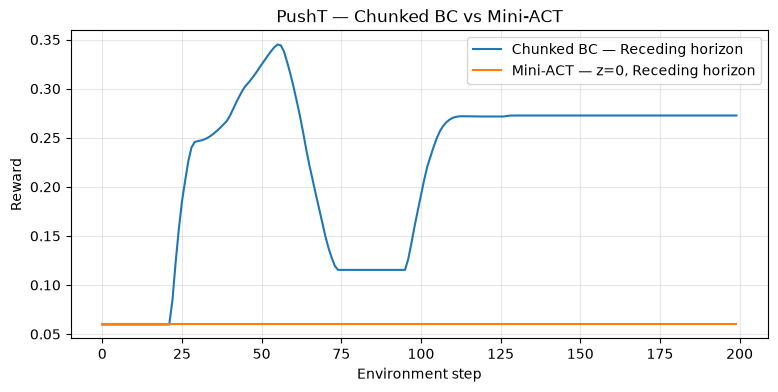

In [55]:
plt.figure(figsize=(9, 4))

plt.plot(
    rh_rewards,
    label="Chunked BC — Receding horizon",
)

plt.plot(
    act_rewards,
    label="Mini-ACT — z=0, Receding horizon",
)

plt.xlabel("Environment step")
plt.ylabel("Reward")
plt.title("PushT — Chunked BC vs Mini-ACT")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 3.5 Investigating the Posterior–Prior Gap

Our Mini-ACT achieves low reconstruction error when
conditioned on the expert action chunk, but performs
poorly when using the prior mean $z=0$.

We investigate whether stronger KL regularization
improves inference-time performance.

We increase the KL weight from $\beta=0.001$ to
$\beta=0.1$ and retrain Mini-ACT from scratch.

We compare posterior reconstruction, prior prediction,
and visual sensitivity.

In [60]:
mini_act = MiniACT(
    horizon=H,
    hidden_dim=128,
    latent_dim=32,
).to(device)

act_optimizer = torch.optim.Adam(
    mini_act.parameters(),
    lr=1e-4,
)

beta = 0.1
num_epochs = 10

In [61]:
act_train_losses = []
act_val_losses = []
act_rec_losses = []
act_kl_losses = []

for epoch in range(num_epochs):

    mini_act.train()
    train_total = train_rec = train_kl = 0.0

    for batch in train_chunk_loader:
        images, states, actions = prepare_chunk_batch(batch)

        predictions, mu, logvar = mini_act(
            images, states, actions
        )

        loss, rec, kl = mini_act_loss(
            predictions, actions, mu, logvar, beta
        )

        act_optimizer.zero_grad()
        loss.backward()
        act_optimizer.step()

        n = images.size(0)
        train_total += loss.item() * n
        train_rec += rec.item() * n
        train_kl += kl.item() * n

    act_train_losses.append(train_total / len(train_chunk_dataset))
    act_rec_losses.append(train_rec / len(train_chunk_dataset))
    act_kl_losses.append(train_kl / len(train_chunk_dataset))

    # Validation with posterior sampling, as in training
    mini_act.eval()
    val_total = 0.0

    with torch.no_grad():
        for batch in val_chunk_loader:
            images, states, actions = prepare_chunk_batch(batch)

            predictions, mu, logvar = mini_act(
                images, states, actions
            )

            loss, _, _ = mini_act_loss(
                predictions, actions, mu, logvar, beta
            )

            val_total += loss.item() * images.size(0)

    act_val_losses.append(val_total / len(val_chunk_dataset))

    print(
        f"Epoch {epoch+1:02d} | "
        f"Train: {act_train_losses[-1]:.4f} | "
        f"Val: {act_val_losses[-1]:.4f} | "
        f"Rec: {act_rec_losses[-1]:.4f} | "
        f"KL: {act_kl_losses[-1]:.4f}"
    )

Epoch 01 | Train: 0.4436 | Val: 0.3120 | Rec: 0.3807 | KL: 0.6288
Epoch 02 | Train: 0.3432 | Val: 0.2879 | Rec: 0.3216 | KL: 0.2156
Epoch 03 | Train: 0.3137 | Val: 0.2801 | Rec: 0.2997 | KL: 0.1396
Epoch 04 | Train: 0.3015 | Val: 0.2713 | Rec: 0.2935 | KL: 0.0796
Epoch 05 | Train: 0.2938 | Val: 0.2680 | Rec: 0.2894 | KL: 0.0439
Epoch 06 | Train: 0.2893 | Val: 0.2708 | Rec: 0.2867 | KL: 0.0260
Epoch 07 | Train: 0.2849 | Val: 0.2630 | Rec: 0.2832 | KL: 0.0169
Epoch 08 | Train: 0.2816 | Val: 0.2589 | Rec: 0.2804 | KL: 0.0118
Epoch 09 | Train: 0.2767 | Val: 0.2566 | Rec: 0.2759 | KL: 0.0086
Epoch 10 | Train: 0.2724 | Val: 0.2529 | Rec: 0.2718 | KL: 0.0066


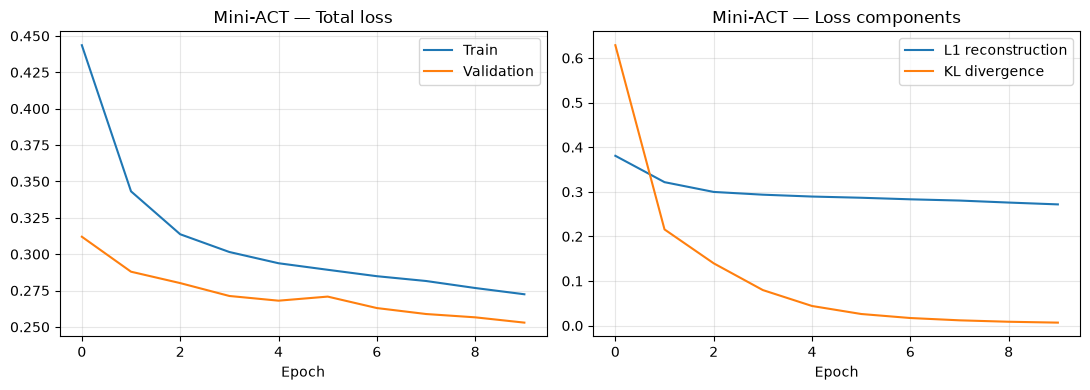

In [62]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(act_train_losses, label="Train")
axes[0].plot(act_val_losses, label="Validation")
axes[0].set_title("Mini-ACT — Total loss")
axes[0].set_xlabel("Epoch")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(act_rec_losses, label="L1 reconstruction")
axes[1].plot(act_kl_losses, label="KL divergence")
axes[1].set_title("Mini-ACT — Loss components")
axes[1].set_xlabel("Epoch")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [63]:
mini_act.eval()

posterior_mse = 0.0
prior_mse = 0.0
shuffled_mse = 0.0
total_samples = 0

rng = np.random.default_rng(42)

with torch.no_grad():
    for batch in val_chunk_loader:
        images, states, actions = prepare_chunk_batch(batch)
        n = images.size(0)

        # Posterior: expert actions available
        posterior_pred, _, _ = mini_act(
            images, states, actions
        )

        # Prior: z = 0, no expert actions
        prior_pred, _, _ = mini_act(
            images, states
        )

        # Prior with shuffled images
        permutation = torch.as_tensor(
            rng.permutation(n),
            device=images.device,
        )

        shuffled_pred, _, _ = mini_act(
            images[permutation],
            states,
        )

        posterior_mse += F.mse_loss(
            posterior_pred, actions
        ).item() * n

        prior_mse += F.mse_loss(
            prior_pred, actions
        ).item() * n

        shuffled_mse += F.mse_loss(
            shuffled_pred, actions
        ).item() * n

        total_samples += n

posterior_mse /= total_samples
prior_mse /= total_samples
shuffled_mse /= total_samples

print(f"Mini-ACT posterior MSE: {posterior_mse:.5f}")
print(f"Mini-ACT prior MSE:     {prior_mse:.5f}")
print(f"Shuffled images MSE:   {shuffled_mse:.5f}")
print(f"Visual sensitivity:    {shuffled_mse - prior_mse:+.5f}")
print(f"Chunked BC MSE:        {correct_mse:.5f}")

Mini-ACT posterior MSE: 0.12428
Mini-ACT prior MSE:     0.12412
Shuffled images MSE:   0.24994
Visual sensitivity:    +0.12582
Chunked BC MSE:        0.10424


In [65]:
env_act = gym.make(
    "gym_pusht/PushT-v0",
    obs_type="state",
    render_mode="rgb_array",
)

obs, info = env_act.reset(seed=42)

act_rewards = []
act_frames = [env_act.render()]

terminated = truncated = False

for t in range(200):
    chunk = predict_mini_act_chunk(
        mini_act,
        env_act.render(),
        obs[:2],
    )

    action = chunk[0].astype(np.float32)

    obs, reward, terminated, truncated, info = env_act.step(action)

    act_rewards.append(reward)

    if (t + 1) % 10 == 0:
        act_frames.append(env_act.render())

    if terminated or truncated:
        break

env_act.close()

print(f"Maximum reward: {max(act_rewards):.4f}")
print(f"Final reward:   {act_rewards[-1]:.4f}")
print(f"Peak step:      {np.argmax(act_rewards)}")

Maximum reward: 0.0598
Final reward:   0.0000
Peak step:      0


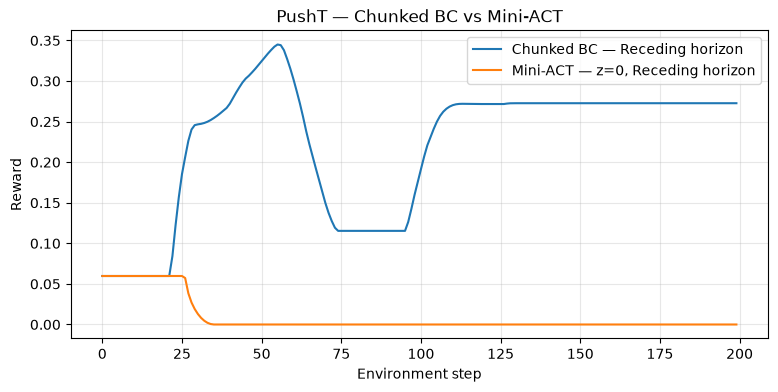

In [66]:
plt.figure(figsize=(9, 4))

plt.plot(
    rh_rewards,
    label="Chunked BC — Receding horizon",
)

plt.plot(
    act_rewards,
    label="Mini-ACT — z=0, Receding horizon",
)

plt.xlabel("Environment step")
plt.ylabel("Reward")
plt.title("PushT — Chunked BC vs Mini-ACT")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 4. Conclusions

We compared three visuomotor imitation learning architectures
on PushT:

1. Single-action Behavior Cloning
2. Chunked Behavior Cloning
3. Mini-ACT with a CVAE and Transformer decoder

Single-action BC learned a near-identity mapping and largely
ignored visual observations.

Chunked BC learned visually conditioned action sequences
and achieved meaningful, but incomplete, object manipulation.
Receding-horizon execution produced the best final reward
in our evaluation episode.

Mini-ACT exposed an important posterior-prior mismatch.
Increasing KL regularization reduced this mismatch and
improved visual sensitivity, but did not improve closed-loop
control in our experiment.

These experiments highlight three central lessons:

- Offline imitation loss is not sufficient to evaluate control.
- Action representation and execution strategy matter.
- Latent-variable policies must be evaluated under their
  actual inference-time conditions.

The next notebook investigates richer visual representations
for robot learning.